**Aceleradores de Hardware - Ordem de Custo**

CPU

GPUs: T4

GPUs: L4

TPU v5e-1

TPU v6e-1

GPUs: A100

GPUs: G4

GPUs: H100

### Import Libraries and Set the intial variables

In [38]:
#!pip install transformers

In [39]:
# Import necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib import rc
from pylab import rcParams

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from collections import defaultdict
from textwrap import wrap
from sklearn.feature_extraction.text import TfidfVectorizer

# Torch ML libraries
import transformers

from transformers import BertModel, AutoTokenizer, get_linear_schedule_with_warmup
import torch
from torch.optim import AdamW

from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from sklearn.ensemble import RandomForestClassifier
# Misc.
import warnings
warnings.filterwarnings('ignore')

In [40]:
# Set intial variables and constants
%config InlineBackend.figure_format='retina'

# Graph Designs
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
HAPPY_COLORS_PALETTE = ["#01BEFE", "#FFDD00", "#FF7D00", "#FF006D", "#ADFF02", "#8F00FF"]
sns.set_palette(sns.color_palette(HAPPY_COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8

# Random seed for reproducibilty
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Set GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


##Parametrização conforme ambiente de execução.

In [41]:
from logging import WARN
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
BASE_PATH_GENERAL = '/content/drive/MyDrive/_Mestrado PUCPR/'
BASE_PATH_DATASET = f'{BASE_PATH_GENERAL}Datasets/'
MODEL_CHECKPOINT = 'rufimelo/Legal-BERTimbau-large'
TEST_SIZE_SPLIT = 0.20
RANDOM_STATE = 42
EPOCHS = 200
APPROACH_EXECUTION = 'epoch' #'step'
LAYERS_TO_FREEZE = 24
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOPPING = 5
class_names = ['Desfavorável ao Réu', 'Favorável ao Réu']
MAX_LEN = 512

# Performance knobs
NUM_WORKERS = 2

In [43]:
#%run "{BASE_PATH_GENERAL}libs/preprocessing_pucpr.ipynb"

In [44]:
import os

# Paths padrão para reprodutibilidade
source_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_undersampling_2021_2026.csv"
train_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_under_2021_2026_treino.csv"
test_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_under_2021_2026_teste.csv"

# Lógica única de carregamento/divisão:
# 1) Se treino e teste já existem, reutiliza diretamente.
# 2) Caso contrário, abre o dataset fonte, divide (randomico + estratificado) e persiste os dois arquivos.
if os.path.exists(train_path) and os.path.exists(test_path):
    print("Arquivos de treino e teste encontrados. Reutilizando arquivos persistidos...")
    df_train = pd.read_csv(train_path, sep=';')
    df_test = pd.read_csv(test_path, sep=';')

    # Mantém compatibilidade com as células que usam 'df'
    df = pd.concat([df_train, df_test], ignore_index=True)

    print(f"Treino carregado de: {train_path} | shape: {df_train.shape}")
    print(f"Teste carregado de: {test_path} | shape: {df_test.shape}")
    print(f"Dataset combinado (df) | shape: {df.shape}")
else:
    print("Arquivos de treino/teste não encontrados. Carregando dataset fonte e gerando split...")
    try:
        df = pd.read_csv(source_path, sep=';')
        print(f"Dataset fonte carregado de: {source_path}")
        print(f"Shape dataset fonte: {df.shape}")

        if 'DECISAO_FAVORAVEL' not in df.columns:
            raise KeyError("Coluna 'DECISAO_FAVORAVEL' não encontrada para estratificação.")

        # Split randômico e estratificado pela classe DECISAO_FAVORAVEL
        df_train, df_test = train_test_split(
            df,
            test_size=TEST_SIZE_SPLIT,
            random_state=RANDOM_STATE,
            stratify=df['DECISAO_FAVORAVEL']
        )

        os.makedirs(BASE_PATH_DATASET, exist_ok=True)
        df_train.to_csv(train_path, sep=';', index=False)
        df_test.to_csv(test_path, sep=';', index=False)

        print(f"Treino gerado e salvo em: {train_path} | shape: {df_train.shape}")
        print(f"Teste gerado e salvo em: {test_path} | shape: {df_test.shape}")
        print("Distribuição DECISAO_FAVORAVEL (treino):")
        print(df_train['DECISAO_FAVORAVEL'].value_counts(normalize=True).round(4))
        print("Distribuição DECISAO_FAVORAVEL (teste):")
        print(df_test['DECISAO_FAVORAVEL'].value_counts(normalize=True).round(4))
        display(df.head(3))
    except FileNotFoundError:
        print(f"Erro: dataset fonte não encontrado em {source_path}")
    except Exception as e:
        print(f"Erro ao processar os dados: {e}")

Arquivos de treino e teste encontrados. Reutilizando arquivos persistidos...
Treino carregado de: /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_under_2021_2026_treino.csv | shape: (4976, 22)
Teste carregado de: /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_under_2021_2026_teste.csv | shape: (1244, 22)
Dataset combinado (df) | shape: (6220, 22)


In [45]:
total   = df.shape[0]
label_s = df[df['DECISAO_FAVORAVEL']  == 'S'].shape[0]
label_n = df[df['DECISAO_FAVORAVEL']  == 'N'].shape[0]

print(f'TOTAL  : {total}')
print(f'LABEL S: {label_s} - % {round(label_s/total*100, 2)}')
print(f'LABEL N: {label_n} - % {round(label_n/total*100, 2)}')

TOTAL  : 6220
LABEL S: 3110 - % 50.0
LABEL N: 3110 - % 50.0


In [46]:
# Function para converter a decisão em num valor contínuo
def cast_decisao_to_int(decisao_favoravel):

    # Convert to class
    if decisao_favoravel == 'S':
        return 1
    else:
        return 0

# Apply to the dataset
df['classe'] = df.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

In [47]:
df['classe'].value_counts()

,count
classe,
0,3110
1,3110


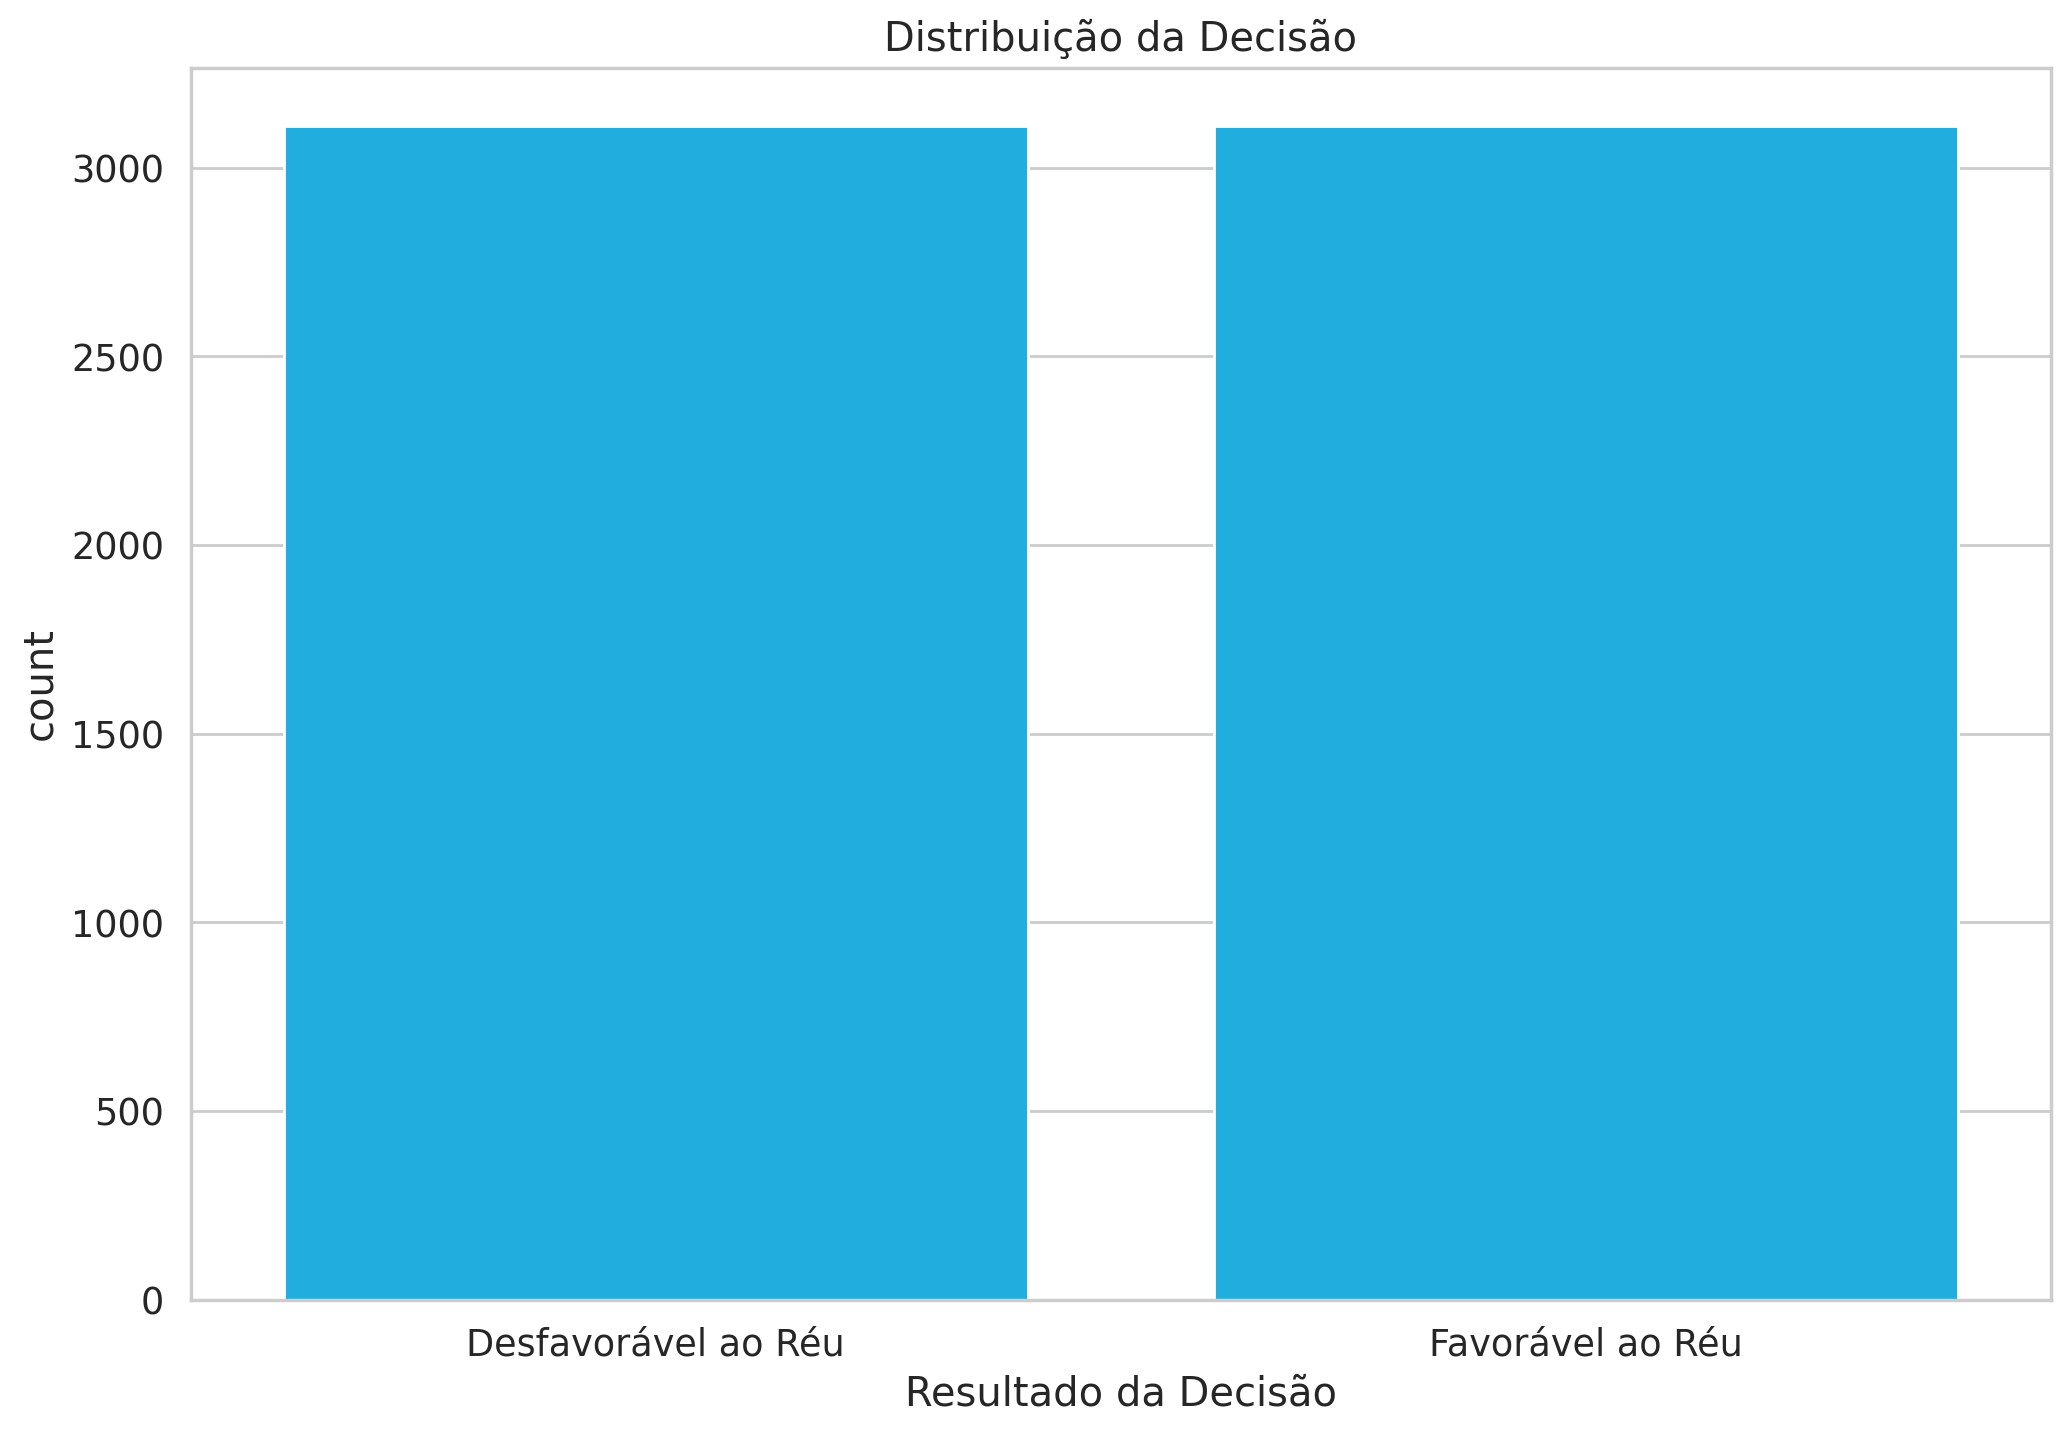

In [48]:
# Garantindo a ordem explícita das classes no gráfico (0 e 1)
ax = sns.countplot(x='classe', data=df, order=[1, 0])

# Fixando os ticks e os rótulos para refletir exatamente os valores 0 e 1
ax.set_xticks([1, 0])
ax.set_xticklabels(['Favorável ao Réu', 'Desfavorável ao Réu'])

plt.xlabel('Resultado da Decisão')
plt.title('Distribuição da Decisão')
plt.show()

In [49]:
# df[df['classe']==1]['RELATORIO'].tolist()[:2]

In [50]:
# df[df['classe']==0]['RELATORIO'].tolist()[:2]

In [51]:
#df['RELATORIO'] = df.RELATORIO.apply(pre_processamento)

In [52]:
# df[df['classe']==1]['RELATORIO'].tolist()[:1]

# BERT

In [53]:
# Build a BERT based tokenizer (fast Rust implementation)
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=True)

In [54]:
# Some of the common BERT tokens
print(tokenizer.sep_token, tokenizer.sep_token_id) # marker for ending of a sentence
print(tokenizer.cls_token, tokenizer.cls_token_id) # start of each sentence, so BERT knows we’re doing classification
print(tokenizer.pad_token, tokenizer.pad_token_id) # special token for padding
print(tokenizer.unk_token, tokenizer.unk_token_id) # tokens not found in training set

[SEP] 102
[CLS] 101
[PAD] 0
[UNK] 100


BERT works with fixed-length sequences. We’ll use a simple strategy to choose the max length. Let’s store the token length of each review.

In [55]:
# # Store length of each review
# token_lens = []

# # Iterate through the content slide
# for text in df.RELATORIO:
#     #tokens = tokenizer.encode(text, max_length=1024)
#     tokens = tokenizer.encode(text)
#     token_lens.append(len(tokens))

In [56]:
# tokens_test = tokenizer.encode("O Habeas Corpus tem natureza constitucional.", truncation=True, max_length=160)
# #
# tokens_test

In [57]:
# for token in tokens_test:
#     print(f"token: {token} | value: {tokenizer.decode(token)}")

In [58]:
#get_word_from_token_id(101, tokenizer)
# tokenizer.convert_ids_to_tokens(101)

In [59]:
# tokenizer.decode(102)

In [60]:
# plt.figure(figsize=(12, 6))
# # Criando o gráfico de barras (histograma) das contagens absolutas
# sns.histplot(token_lens, bins=50, kde=False, color='#01BEFE')

# plt.title('Distribuição da Quantidade de Tokens por Registro')
# plt.xlabel('Quantidade de Tokens')
# plt.ylabel('Total de Registros')
# plt.xlim([0, 2000]) # Limitando o eixo x conforme o seu distplot anterior
# plt.show()

In [61]:
# plot the distribution of review lengths
# sns.distplot(token_lens)
# plt.xlim([0, 2000]);
# plt.xlabel('Token count')

### Preparing Torch Dataset

To enter data into a PyTorch, we need a more robust data generator class. We will return the review text as well to validate our predictions easily.

###  `HCAcordaoSTJ` (Custom Dataset)

A classe `HCAcordaoSTJ` (que herda de `torch.utils.data.Dataset`) atua como uma **ponte essencial entre os seus dados brutos e o modelo PyTorch/HuggingFace**. A criação desta classe customizada é uma prática padrão e necessária pelos seguintes motivos:

1. **Contrato com o PyTorch (`DataLoader`)**: Para que o `DataLoader` consiga gerenciar os lotes (batches), embaralhar os dados e usar múltiplos processadores, ele precisa saber como interagir com seus dados. O PyTorch exige que você implemente um contrato básico usando dois métodos:
   * `__len__`: Informa ao DataLoader o tamanho total do dataset.
   * `__getitem__`: Ensina o DataLoader a extrair e processar uma única linha (amostra) com base em um índice.

2. **Tokenização *On-the-Fly* (Sob Demanda) e Eficiência de Memória**: O método `__getitem__` aplica o `tokenizer` do HuggingFace individualmente em cada texto *apenas no momento em que a amostra é chamada* durante o treinamento. Em vez de tokenizar todo o seu dataset de 6336 acórdãos de uma vez e armazenar matrizes gigantescas na memória RAM, a transformação é feita lote a lote.

3. **Formatação Exigida pelo BERT**: Modelos da biblioteca `transformers` do HuggingFace não aceitam texto puro (strings). Eles esperam tensores (matrizes numéricas do PyTorch) com chaves muito específicas. O método `__getitem__` prepara e empacota exatamente o que o BERT precisa:
   * **`input_ids`**: O texto mapeado para os números do vocabulário do modelo.
   * **`attention_mask`**: Uma máscara de 1s e 0s que ensina o modelo a olhar apenas para as palavras reais e ignorar os espaços vazios (*padding*).

4. **Padronização Universal (*Padding* e *Truncation*)**: Redes neurais precisam que todas as entradas de um lote tenham o mesmo tamanho matemático. Como os acórdãos variam de tamanho, a classe força com que todos tenham exatamente `max_len` (no seu caso, 512 tokens). Textos menores são preenchidos com zeros (`padding='max_length'`) e textos maiores são cortados (`truncation=True`).

5. **Empacotamento dos Alvos (*Targets*)**: Além de formatar a entrada para o HuggingFace, a classe converte as suas classes (0 ou 1) no formato `torch.long`, que é o tipo de dado estritamente exigido pela função de perda (`CrossEntropyLoss`) do PyTorch durante a etapa de otimização.

Em resumo, o `HCAcordaoSTJ` é o "tradutor" que pega suas strings do Pandas e as transforma perfeitamente no idioma matemático e estrutural que o BERT e o PyTorch entendem.

In [62]:
from typing import Dict, Union
import numpy as np
import torch
from torch.utils.data import Dataset

class HCAcordaoSTJ(Dataset):
    def __init__(self, reports: np.ndarray, targets: np.ndarray, tokenizer, max_len: int) -> Dataset:
        self.reports = reports.astype(str)
        self.targets = targets

        # Tokeniza em lote uma vez para reduzir custo por época
        encodings = tokenizer(
            self.reports.tolist(),
            add_special_tokens=True,
            max_length=max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True
        )

        self.input_ids = torch.tensor(encodings['input_ids'], dtype=torch.long)
        self.attention_mask = torch.tensor(encodings['attention_mask'], dtype=torch.long)

    def __len__(self) -> int:
        return len(self.reports)

    def __getitem__(self, item: int) -> Dict[str, Union[str, torch.Tensor]]:
        return {
            'report_text': self.reports[item],
            'input_ids': self.input_ids[item],
            'attention_mask': self.attention_mask[item],
            'targets': torch.tensor(self.targets[item], dtype=torch.long)
        }

### Otimização de Memória
Manter apenas as colunas estritamente necessárias para o treinamento do modelo.

In [63]:
import gc

# Criar um novo DataFrame apenas com as colunas necessárias
df_clean = df[['RELATORIO', 'classe']].copy()

# Excluir o dataframe antigo da memória e forçar a coleta de lixo
del df
gc.collect()

# Renomear de volta para 'df' para manter a compatibilidade com o código abaixo
df = df_clean

print("Memória otimizada. Colunas atuais:", df.columns.tolist())
print("Novo shape do DataFrame:", df.shape)
display(df.head(3))

Memória otimizada. Colunas atuais: ['RELATORIO', 'classe']
Novo shape do DataFrame: (6220, 2)


,RELATORIO,classe
0,Trata-se de agravo regimental interposto pelo ...,0
1,Trata-se de agravo regimental interposto por E...,0
2,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,0


Create a 80% train data and 20% test.

In [64]:
# Split já é tratado na célula de carga inteligente (Célula 10).
# Aqui apenas conferimos os dataframes finais para manter compatibilidade do fluxo.
if 'df_train' not in globals() or 'df_test' not in globals():
    raise RuntimeError("Execute primeiro a célula de carga inteligente para criar/carregar treino e teste.")

print(f"Train shape: {df_train.shape}")
print(f"Test shape: {df_test.shape}")

Train shape: (4976, 22)
Test shape: (1244, 22)


In [65]:
#Você parou nesta etapa. Agora vc precisa estudar em detalhes a classe DataLoader e as implicações com o treinamento.

Create a dataloader to release data in batches.

### O papel do DataLoader neste treinamento

O `DataLoader` em PyTorch é uma utilidade fundamental para o treinamento de modelos de aprendizado profundo, especialmente com grandes conjuntos de dados. No contexto deste treinamento BERT, ele desempenha vários papéis cruciais:

1.  **Iteração em Lotes (Batching)**: Ele agrupa os dados em pequenos lotes (definidos por `batch_size`). Em vez de alimentar uma única amostra para o modelo por vez (o que é ineficiente para GPUs), o `DataLoader` fornece um lote de amostras. Isso permite que o modelo processe várias entradas simultaneamente, acelerando o treinamento e aproveitando a paralelização do hardware.

2.  **Embaralhamento (Shuffling)**: Antes de cada época de treinamento, o `DataLoader` (se configurado com `shuffle=True`, embora neste notebook esteja implícito que não está explícito no `create_data_loader` mas é uma prática comum para o treinamento) embaralha os dados. Isso é vital para garantir que o modelo não aprenda a ordem dos dados e para evitar que a ordem das amostras introduza vieses no treinamento.

3.  **Processamento Multiprocessado (`num_workers`)**: O parâmetro `num_workers` permite que os dados sejam carregados e pré-processados em paralelo por múltiplos processos secundários (em vez do processo principal). Isso é particularmente útil quando o pré-processamento de dados é uma etapa demorada (como a tokenização e o padding feitos na classe `HCAcordaoSTJ`), pois evita gargalos no carregamento de dados que poderiam deixar a GPU ociosa.

4.  **Integração com `Dataset`**: O `DataLoader` trabalha em conjunto com a classe `Dataset` (neste caso, `HCAcordaoSTJ`). A classe `Dataset` é responsável por como as amostras individuais são carregadas e pré-processadas (tokenização, truncamento, padding, etc.), enquanto o `DataLoader` é responsável por como essas amostras individuais são agrupadas e fornecidas ao modelo em lotes.

Em resumo, o `DataLoader` otimiza o fluxo de dados do disco para a memória e, em seguida, para o modelo, garantindo que o treinamento seja eficiente, reprodutível (com `random_state`) e que o modelo veja os dados de forma variada ao longo das épocas, o que é fundamental para um bom desempenho e generalização.

In [66]:
import os

def create_data_loader(df: pd.DataFrame, tokenizer, max_len: int, batch_size: int, shuffle: bool = False) -> DataLoader:
    ds = HCAcordaoSTJ(
        reports=df.RELATORIO.to_numpy(),
        targets=df.classe.to_numpy(),
        tokenizer=tokenizer,
        max_len=max_len
    )

    workers = min(NUM_WORKERS, os.cpu_count() or 1)

    loader_kwargs = {
        'dataset': ds,
        'batch_size': batch_size,
        'shuffle': shuffle,
        'num_workers': workers,
        'pin_memory': (device.type == 'cuda')
    }

    if workers > 0:
        loader_kwargs['persistent_workers'] = True
        loader_kwargs['prefetch_factor'] = 2

    return DataLoader(**loader_kwargs)

In [67]:
# Create train and test data loaders
# Ensure 'classe' column is present in df_train and df_test
# This is needed because df_train and df_test were created before the 'classe' column was added to the main 'df'.
if 'DECISAO_FAVORAVEL' in df_train.columns and 'classe' not in df_train.columns:
    df_train['classe'] = df_train.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)
if 'DECISAO_FAVORAVEL' in df_test.columns and 'classe' not in df_test.columns:
    df_test['classe'] = df_test.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

train_data_loader = create_data_loader(df_train, tokenizer, MAX_LEN, BATCH_SIZE, shuffle=True)
test_data_loader = create_data_loader(df_test, tokenizer, MAX_LEN, BATCH_SIZE, shuffle=False)

In [68]:
# Examples
data = next(iter(train_data_loader))
print(data.keys())

print(data['input_ids'].shape)
print(data['attention_mask'].shape)
print(data['targets'].shape)

dict_keys(['report_text', 'input_ids', 'attention_mask', 'targets'])
torch.Size([16, 512])
torch.Size([16, 512])
torch.Size([16])


## Sentiment Classification with BERT and Hugging Face

We’ll use the basic BertModel and build our sentiment classifier on top of it. Let’s load the model

##### Load the basic BERT model
bert_model = BertModel.from_pretrained(MODEL_NAME)

We use a dropout layer for some regularization and a fully-connected layer for our output. We are returning the raw output of the last layer since that is required for the cross-entropy loss function in PyTorch to work. Create an instance and move it to the GPU

In [69]:
# Load the basic BERT model
#bert_model = BertModel.from_pretrained(MODEL_CHECKPOINT)
from transformers import AutoTokenizer, AutoModelForSequenceClassification # Or BertTokenizer, BertForSequenceClassification

#bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_CHECKPOINT, num_labels=2)

In [70]:
# num_layers_to_freeze = LAYERS_TO_FREEZE
# print(f"Freezing the embeddings and the first {num_layers_to_freeze} encoder layers of the model...")

# for name, param in bert_model.named_parameters():
#     if 'embeddings' in name:
#         param.requires_grad = False
#     elif 'encoder.layer' in name:
#         # Extrai o número da camada pelo nome (ex: bert.encoder.layer.0.attention...)
#         layer_num = int(name.split('.')[3])
#         if layer_num < num_layers_to_freeze:
#             param.requires_grad = False
#         else:
#             # Garante que camadas subsequentes sejam treináveis
#             param.requires_grad = True
#     else:
#         # O pooler e o classifier (camadas finais) continuam treináveis
#         param.requires_grad = True

# print("Layers freezing complete. You can now proceed with training.")

In [71]:
# Print layer names
# The index can help you identify which layers correspond to earlier blocks (e.g., embedding, early encoder layers)
# i = 0
# for name, param in bert_model.named_parameters():
#   i = i + 1
#   print(f"index: {i} {name} - status: {param.requires_grad}")

In [72]:
#os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

### O papel da classe `HCAcordaoClassifier` no Fine-Tuning

A classe `HCAcordaoClassifier` é o coração do seu processo de *fine-tuning*. Ela herda de `nn.Module` (a classe base para todas as redes neurais no PyTorch) e tem a função de **adaptar um modelo de linguagem genérico para a sua tarefa específica** de classificação binária (Favorável vs. Desfavorável).

Com as recentes modificações, a arquitetura ficou mais profunda e robusta. Aqui está o que cada parte faz e onde exatamente estão as camadas *fully connected*:

1. **A Base (O "Cérebro" Pré-treinado): `self.bert`**
   * Utilizamos o `BertModel.from_pretrained()` do Hugging Face.
   * O BERT atua como um poderoso **extrator de características**. Ele lê o texto e o transforma em uma rica representação matemática (um vetor de 768 dimensões).

2. **Camadas Intermediárias (Rede Fully Connected / Multi-Layer Perceptron)**
   * Em vez de ligar o BERT direto na saída, criamos uma rede neural intermediária mais profunda com três camadas lineares (`self.fc1`, `self.fc2`, `self.fc3`).
   * **É aqui que começa a sua rede *fully connected* (totalmente conectada)**, construída com `nn.Linear`. O fluxo expande a capacidade de aprendizado projetando as 768 dimensões iniciais para **4000 neurônios**, funilando depois para **2000** e, em seguida, para **1000 neurônios**. Em uma camada *fully connected*, todos os neurônios se conectam a todos os neurônios da camada seguinte, permitindo que o modelo aprenda padrões semânticos jurídicos altamente complexos.

3. **Ativação (`ReLU`) e Regularização (`Dropout`)**
   * **`ReLU`:** Aplicada após cada camada intermediária *fully connected*, é a função matemática não-linear que permite à rede extrair e combinar características de maneira mais complexa.
   * **`Dropout` (p=0.3):** Desliga aleatoriamente 30% dos neurônios durante o treinamento. É absolutamente crucial nesta arquitetura grande (com muitos parâmetros) para combater o *overfitting* (impedir que o modelo apenas "decore" os dados de treino).

4. **A Cabeça de Classificação (A última Fully Connected): `self.out`**
   * A camada `self.out`, definida como `nn.Linear(1000, n_classes)`, é a **última camada *fully connected*** da sua rede. Pega os 1000 neurônios da última camada oculta e os reduz para apenas **2 números** (suas `n_classes`), que representarão as predições brutas (logits) do acórdão ser Favorável ou Desfavorável.

5. **O Fluxo de Dados: Método `forward`**
   * Recebe os `input_ids` e a `attention_mask` (fornecidos pelo `DataLoader`).
   * O BERT processa o texto e fornece o **`pooler_output`** (o "resumo" do texto baseado no token especial `[CLS]`).
   * Esse vetor de resumo passa sequencialmente pelos blocos *fully connected* da seguinte forma: `Camada Linear -> ReLU -> Dropout`.
   * Finalmente, passa por `self.out` para dar o veredito final.

In [73]:
class HCAcordaoClassifier(nn.Module):

    def __init__(self, n_classes: int, num_layers_to_freeze: int, model_name: str) -> None:
        super(HCAcordaoClassifier, self).__init__()
        # Utilizamos o BertModel puro (base) para extração de features
        self.bert = BertModel.from_pretrained(model_name)

        # Cabeça de classificação mais enxuta para reduzir memória e custo computacional
        self.fc1 = nn.Linear(self.bert.config.hidden_size, 4000)
        self.drop1 = nn.Dropout(p=0.3)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(4000, 2000)
        self.drop2 = nn.Dropout(p=0.3)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(2000, 1000)
        self.drop3 = nn.Dropout(p=0.3)
        self.relu3 = nn.ReLU()

        # Camada final de classificação
        self.out = nn.Linear(1000, n_classes)

        # Executa o congelamento das camadas logo após a inicialização
        self.freeze_layers(num_layers_to_freeze)

    def freeze_layers(self, num_layers_to_freeze: int) -> None:
      print(f"Freezing the embeddings and the first {num_layers_to_freeze} encoder layers of the model...")

      for name, param in self.bert.named_parameters():
          if 'embeddings' in name:
              param.requires_grad = False
          elif 'encoder.layer' in name:
              # Extrai o número da camada pelo nome (ex: encoder.layer.0.attention...)
              layer_num = int(name.split('.')[2])
              if layer_num < num_layers_to_freeze:
                  param.requires_grad = False
              else:
                  # Garante que camadas subsequentes sejam treináveis
                  param.requires_grad = True
          else:
              # O pooler e o classifier (camadas finais) continuam treináveis
              param.requires_grad = True

      print("Layers freezing complete. You can now proceed with training.")

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        # Saída do BERT
        output = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Representação inicial da sentença (pooled_output)
        cls_embedding = output.pooler_output

        # Passagem pelas camadas intermediárias (hidden layers)
        hidden = self.fc1(cls_embedding)
        hidden = self.relu1(hidden)
        hidden = self.drop1(hidden)

        hidden = self.fc2(hidden)
        hidden = self.relu2(hidden)
        hidden = self.drop2(hidden)

        hidden = self.fc3(hidden)
        hidden = self.relu3(hidden)
        hidden = self.drop3(hidden)

        # Saída final crua
        logits = self.out(hidden)

        return logits


In [74]:
# Instantiate the model and move to classifier
model = HCAcordaoClassifier(len(class_names), LAYERS_TO_FREEZE, MODEL_CHECKPOINT)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# O config pertence ao modelo base do BERT (self.bert na nossa classe)
print(model.bert.config.hidden_size)


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: rufimelo/Legal-BERTimbau-large
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing the embeddings and the first 24 encoder layers of the model...
Layers freezing complete. You can now proceed with training.
1024


#### Model Characterstics

In [75]:
# Number of hidden units
# from transformers import BertModel

# bert_model = BertModel.from_pretrained(MODEL_CHECKPOINT)
# print(bert_model.config.hidden_size)

### Training Phase


we’ll use the AdamW optimizer provided by Hugging Face. It corrects weight decay. We’ll also use a linear scheduler with no warmup

In [76]:
from torch.optim import AdamW

# Optimizer Adam utilizando os hiperparâmetros globais definidos anteriormente
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Number of iterations usando a variável global EPOCHS
total_steps = len(train_data_loader) * EPOCHS

# Calculando os passos de warmup com base no WARMUP_RATIO
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Set the loss function
loss_fn = nn.CrossEntropyLoss().to(device)

# AMP acelera treino em GPU e reduz uso de memória
use_amp = (device.type == 'cuda')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


In [77]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Function for a single training iteration
def train_epoch(model, data_loader, loss_fn, optimizer, device, scheduler, n_examples, scaler, use_amp):
    model = model.train()
    losses = []
    correct_predictions = 0
    all_preds = []
    all_targets = []

    optimizer.zero_grad(set_to_none=True)

    for d in data_loader:
        input_ids = d["input_ids"].to(device, non_blocking=True)
        attention_mask = d["attention_mask"].to(device, non_blocking=True)
        targets = d["targets"].to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            loss = loss_fn(outputs, targets)

        _, preds = torch.max(outputs, dim=1)

        correct_predictions += torch.sum(preds == targets)
        losses.append(loss.item())

        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

        # Backward prop (mixed precision)
        scaler.scale(loss).backward()

        # Gradient Descent
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)

    acc = (correct_predictions.double() / n_examples).item()
    loss_val = np.mean(losses)
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return acc, loss_val, precision, recall, f1


Write a function to evaluate model performance

In [78]:
def eval_model(model, data_loader, loss_fn, device, n_examples, use_amp=False):
    model = model.eval()

    losses = []
    correct_predictions = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for d in data_loader:
            input_ids = d["input_ids"].to(device, non_blocking=True)
            attention_mask = d["attention_mask"].to(device, non_blocking=True)
            targets = d["targets"].to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                # Get model ouptuts
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )
                loss = loss_fn(outputs, targets)

            _, preds = torch.max(outputs, dim=1)

            correct_predictions += torch.sum(preds == targets)
            losses.append(loss.item())

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    acc = (correct_predictions.double() / n_examples).item()
    loss_val = np.mean(losses)
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return acc, loss_val, precision, recall, f1


Write the training Loop and store the best training state.

In [ ]:
%%time
import os
import copy
from collections import defaultdict

history = defaultdict(list)
best_recall = 0
best_model_weights = None

# Parâmetros para o Early Stopping
patience = EARLY_STOPPING
epochs_no_improve = 0

# Garantir que a pasta models exista
model_dir = f'{BASE_PATH_GENERAL}models'
os.makedirs(model_dir, exist_ok=True)
model_save_path = f'{model_dir}/best_model_state_bertimbau_large.bin'

for epoch in range(EPOCHS):

    # Show details
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("-" * 70)

    train_acc, train_loss, train_prec, train_rec, train_f1 = train_epoch(
        model,
        train_data_loader,
        loss_fn,
        optimizer,
        device,
        scheduler,
        len(df_train),
        scaler,
        use_amp
    )

    print(f"Train loss {train_loss:.4f} accuracy {train_acc:.4f} precision {train_prec:.4f} recall {train_rec:.4f} f1 {train_f1:.4f}")

    # Get model performance on test set
    test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
        model,
        test_data_loader,
        loss_fn,
        device,
        len(df_test),
        use_amp
    )

    print(f"Test  loss {test_loss:.4f} accuracy {test_acc:.4f} precision {test_prec:.4f} recall {test_rec:.4f} f1 {test_f1:.4f}")
    print()

    history['train_acc'].append(round(train_acc, 5))
    history['train_loss'].append(round(train_loss, 5))
    history['train_prec'].append(round(train_prec, 5))
    history['train_rec'].append(round(train_rec, 5))
    history['train_f1'].append(round(train_f1, 5))

    history['test_acc'].append(round(test_acc, 5))
    history['test_loss'].append(round(test_loss, 5))
    history['test_prec'].append(round(test_prec, 5))
    history['test_rec'].append(round(test_rec, 5))
    history['test_f1'].append(round(test_f1, 5))

    # If we beat prev performance
    if test_rec > best_recall:
        best_model_weights = copy.deepcopy(model.state_dict())
        best_recall = test_rec
        epochs_no_improve = 0 # Reseta o contador ao melhorar
    else:
        epochs_no_improve += 1
        print(f"Sem melhoras no teste por {epochs_no_improve} época(s).")
        if epochs_no_improve >= patience:
            print(f"Early Stopping acionado! Treinamento interrompido na época {epoch + 1}.")
            break

# Após o término do treinamento, salva o melhor modelo em disco
if best_model_weights is not None:
    torch.save(best_model_weights, model_save_path)
    print(f"Treinamento finalizado. Melhor modelo (Recall: {best_recall:.4f}) salvo em: {model_save_path}")


Epoch 1/200
----------------------------------------------------------------------
Train loss 0.6922 accuracy 0.5221 precision 0.5233 recall 0.5221 f1 0.5161
Test  loss 0.6899 accuracy 0.5040 precision 0.6147 recall 0.5040 f1 0.3463

Epoch 2/200
----------------------------------------------------------------------
Train loss 0.6875 accuracy 0.5999 precision 0.6012 recall 0.5999 f1 0.5986
Test  loss 0.6782 accuracy 0.6616 precision 0.6890 recall 0.6616 f1 0.6488

Epoch 3/200
----------------------------------------------------------------------
Train loss 0.6719 accuracy 0.6373 precision 0.6391 recall 0.6373 f1 0.6360
Test  loss 0.6437 accuracy 0.6913 precision 0.6960 recall 0.6913 f1 0.6895

Epoch 4/200
----------------------------------------------------------------------
Train loss 0.6421 accuracy 0.6553 precision 0.6580 recall 0.6553 f1 0.6539
Test  loss 0.6436 accuracy 0.6262 precision 0.6903 recall 0.6262 f1 0.5918

Sem melhoras no teste por 1 época(s).
Epoch 5/200
--------------

The above took a lot of time but it's finally working. Now, we can plot the training and validation accuracy.

In [ ]:
plt.plot(history['train_loss'], label='training loss')
plt.plot(history['test_loss'], label='validation loss')

plt.title('Training history')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.ylim([0, 2]);

### Model Evaluation

In [ ]:
# Carrega os melhores pesos encontrados durante o treinamento para avaliação
if 'best_model_weights' in locals() and best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Melhores pesos do modelo carregados para avaliação!")

test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
  model,
  test_data_loader,
  loss_fn,
  device,
  len(df_test),
  use_amp
)

print(f"Test Accuracy: {test_acc:.2f}")
print(f"Test Precision: {test_prec:.2f}")
print(f"Test Recall: {test_rec:.2f}")
print(f"Test F1: {test_f1:.2f}")


Define a helper function to get predictions from our models. This is similar to the evaluation function, except that we’re storing the text of the reviews and the predicted probabilities

In [ ]:
def get_predictions(model, data_loader):
    model = model.eval()

    report_texts = []
    predictions = []
    prediction_probs = []
    real_values = []

    with torch.no_grad():
        for d in data_loader:
            texts = d["report_text"]
            input_ids = d["input_ids"].to(device, non_blocking=True)
            attention_mask = d["attention_mask"].to(device, non_blocking=True)
            targets = d["targets"].to(device, non_blocking=True)

            # Get outputs
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            _, preds = torch.max(outputs, dim=1)

            report_texts.extend(texts)
            predictions.extend(preds)
            prediction_probs.extend(outputs)
            real_values.extend(targets)

    predictions = torch.stack(predictions).cpu()
    prediction_probs = torch.stack(prediction_probs).cpu()
    real_values = torch.stack(real_values).cpu()

    return report_texts, predictions, prediction_probs, real_values

In [ ]:
y_report_texts, y_pred, y_pred_probs, y_test = get_predictions(
    model,
    test_data_loader
)

In [ ]:
print(classification_report(y_test, y_pred, target_names=class_names))

In [ ]:
def show_confusion_matrix(confusion_matrix):
    hmap = sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues")
    hmap.yaxis.set_ticklabels(hmap.yaxis.get_ticklabels(), rotation=0, ha='right')
    hmap.xaxis.set_ticklabels(hmap.xaxis.get_ticklabels(), rotation=30, ha='right')
    plt.ylabel('True sentiment')
    plt.xlabel('Predicted sentiment');

cm = confusion_matrix(y_test, y_pred)
df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)
show_confusion_matrix(df_cm)

### Curva ROC e Métrica AUC
Avaliando a capacidade do modelo de distinguir entre as classes.

In [ ]:
import torch.nn.functional as F
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1. Preparar os dados reais e as probabilidades
# y_test já contém as classes reais geradas pela função get_predictions (0 ou 1)
y_true = y_test.numpy()

# Converter logits (saídas brutas) em probabilidades para a classe positiva (1 - Favorável)
probs = F.softmax(y_pred_probs, dim=1).numpy()
y_scores = probs[:, 1] # Pegando apenas a probabilidade da classe 1

# 2. Calcular FPR (Taxa de Falsos Positivos) e TPR (Taxa de Verdadeiros Positivos)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# 3. Calcular a Área Sob a Curva (AUC)
roc_auc = auc(fpr, tpr)

# 4. Plotar a Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#FF7D00', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')

# Plotar a linha de base (modelo aleatório)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',)

# Configurações do gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC (Base de Teste)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3, linestyle='--')

plt.show()

print(f"Métrica AUC: {roc_auc:.4f}")

## Predicting on raw text

In [ ]:
import torch.nn.functional as F

def BERT_SA(text) :
    encoded_review = tokenizer(
        text,
        max_length=MAX_LEN,
        add_special_tokens=True,
        return_token_type_ids=False,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoded_review['input_ids'].to(device)
    attention_mask = encoded_review['attention_mask'].to(device)

    # Garante que o modelo está no modo de avaliação e economiza memória
    model.eval()
    with torch.no_grad():
        output = model(input_ids, attention_mask)

    # Calcula as probabilidades usando softmax
    probs = F.softmax(output, dim=1)[0]
    _, prediction = torch.max(output, dim=1)

    print(f'Report: {text}\n')
    print(f'Decision  : {class_names[prediction]}')
    print('Probabilidades:')
    print(f' - {class_names[0]}: {probs[0].item() * 100:.2f}%')
    print(f' - {class_names[1]}: {probs[1].item() * 100:.2f}%')


In [ ]:
import torch.nn.functional as F
import torch

def bert_vall(text, valor_real, model):
    encoded_review = tokenizer(
        text,
        max_length=MAX_LEN,
        add_special_tokens=True,
        return_token_type_ids=False,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoded_review['input_ids'].to(device)
    attention_mask = encoded_review['attention_mask'].to(device)

    # Garante que o modelo está no modo de avaliação e economiza memória
    model.eval()
    with torch.no_grad():
        output = model(input_ids, attention_mask)

    # Calcula as probabilidades usando softmax
    probs = F.softmax(output, dim=1)[0]
    prob_desfavoravel = probs[0].item()
    prob_favoravel = probs[1].item()

    # Obtém a classe prevista
    _, prediction = torch.max(output, dim=1)
    predicted_class_idx = prediction.item()
    predicted_class_name = class_names[predicted_class_idx]

    # Compara o valor previsto com o valor real passado
    # Permite comparar passando tanto o int (0 ou 1) quanto a string ('Favorável ao Réu' etc)
    if isinstance(valor_real, int):
        acertou = (predicted_class_idx == valor_real)
    else:
        acertou = (predicted_class_name == valor_real)

    return acertou, prob_desfavoravel, prob_favoravel

# Exemplo de uso:
# acertou, prob_desf, prob_fav = bert_vall("texto do relatorio...", 1, loaded_model)
# print(f"Acertou? {acertou} | Prob. Desfavorável: {prob_desf*100:.2f}% | Prob. Favorável: {prob_fav*100:.2f}%")

In [ ]:
texto = """<br>O ministro relator (SEBASTIÃO REIS): Trata-se de habeas: corpus <b>substitutivo de recurso próprio</b>, com pedido de liminar, impetrado em favor de LUIS FELIPE SILVA DE ASSIS, em que se aponta com autoridade coatora o Tribunal de Justiça do Estado do Rio de Janeiro.Consta dos autos que o paciente foi condenado à pena de 5 anos e 10 meses de reclusão, em regime semiaberto, mais pagamento de 583 dias-multa, como incurso no art. 33,caput, c.c o 40, VI, da Lei n. 11.343/2006.Em sede recursal, o Tribunal de origem negou provimento ao apelo defensivo."""
texto = pre_processamento(texto, mantem_pontuacao='n')

BERT_SA(texto)